# Customer Review Sentiment Analysis Using RNN

This notebook explores the full Amazon fine-food review dataset and then trains an RNN model to classify review sentiment.

I will first understand the data, check its quality, and look at ratings, products, reviewers, dates, and helpful votes. For the model, I will use the review **Summary and Text together**. The star rating will be used to create the sentiment label.

Keep `Reviews.csv` in the same folder as this notebook.

### 1. Import libraries

In [1]:
import re
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, SimpleRNN, Dropout, Dense
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

### 2. Load the complete dataset

In [2]:
df = pd.read_csv("data/Reviews.csv")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
display(df.head())

Number of rows: 568454
Number of columns: 10


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned dog food products and have found them all to be of ...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all","This is a confection that has been around a few centuries. It is a light, pillowy citrus gelati..."
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient in Robitussin I believe I have found it. I got thi...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wide assortment of yummy taffy. Delivery was very qu...


### 3. Understand the columns

In [3]:
column_notes = pd.DataFrame({
    "Column": [
        "Id", "ProductId", "UserId", "ProfileName",
        "HelpfulnessNumerator", "HelpfulnessDenominator",
        "Score", "Time", "Summary", "Text"
    ],
    "Meaning": [
        "Unique review ID",
        "Product being reviewed",
        "Reviewer ID",
        "Reviewer display name",
        "Number of people who found the review helpful",
        "Number of people who voted on helpfulness",
        "Star rating from 1 to 5",
        "Review time stored as a Unix timestamp",
        "Short review heading",
        "Full review written by the customer"
    ]
})
display(column_notes)
df.info()

,Column,Meaning
0,Id,Unique review ID
1,ProductId,Product being reviewed
2,UserId,Reviewer ID
3,ProfileName,Reviewer display name
4,HelpfulnessNumerator,Number of people who found the review helpful
5,HelpfulnessDenominator,Number of people who voted on helpfulness
6,Score,Star rating from 1 to 5
7,Time,Review time stored as a Unix timestamp
8,Summary,Short review heading
9,Text,Full review written by the customer


<class 'pandas.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      568454 non-null  int64
 1   ProductId               568454 non-null  str  
 2   UserId                  568454 non-null  str  
 3   ProfileName             568428 non-null  str  
 4   HelpfulnessNumerator    568454 non-null  int64
 5   HelpfulnessDenominator  568454 non-null  int64
 6   Score                   568454 non-null  int64
 7   Time                    568454 non-null  int64
 8   Summary                 568427 non-null  str  
 9   Text                    568454 non-null  str  
dtypes: int64(5), str(5)
memory usage: 313.1 MB


### 4. Check missing values and duplicates

In [4]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percent": (df.isnull().mean() * 100).round(2)
}).sort_values("Missing_Count", ascending=False)

display(missing_report)
print("Duplicate full rows:", df.duplicated().sum())
print("Duplicate review IDs:", df["Id"].duplicated().sum())

,Missing_Count,Missing_Percent
Summary,27,0.0
ProfileName,26,0.0
ProductId,0,0.0
Id,0,0.0
HelpfulnessNumerator,0,0.0
UserId,0,0.0
HelpfulnessDenominator,0,0.0
Score,0,0.0
Time,0,0.0
Text,0,0.0


Duplicate full rows: 0
Duplicate review IDs: 0


### 5. Clean the data

In [5]:
# Keep a copy of the original data for reference.
df = df.copy()

df["Score"] = pd.to_numeric(df["Score"], errors="coerce")
df["Time"] = pd.to_numeric(df["Time"], errors="coerce")
df["HelpfulnessNumerator"] = pd.to_numeric(df["HelpfulnessNumerator"], errors="coerce")
df["HelpfulnessDenominator"] = pd.to_numeric(df["HelpfulnessDenominator"], errors="coerce")

df["Text"] = df["Text"].fillna("").astype(str)
df["Summary"] = df["Summary"].fillna("").astype(str)
df["ProfileName"] = df["ProfileName"].fillna("Unknown").astype(str)
df["ProductId"] = df["ProductId"].fillna("Unknown").astype(str)
df["UserId"] = df["UserId"].fillna("Unknown").astype(str)

# Remove rows without a usable rating, date, or review text.
df = df.dropna(subset=["Score", "Time"])
df = df[df["Score"].isin([1, 2, 3, 4, 5])]
df = df[df["Text"].str.strip() != ""].copy()

# Each review ID should appear once.
df = df.drop_duplicates(subset=["Id"]).reset_index(drop=True)

df["Score"] = df["Score"].astype(int)
df["HelpfulnessNumerator"] = df["HelpfulnessNumerator"].fillna(0)
df["HelpfulnessDenominator"] = df["HelpfulnessDenominator"].fillna(0)

df["ReviewDate"] = pd.to_datetime(df["Time"], unit="s", errors="coerce")
df = df.dropna(subset=["ReviewDate"]).copy()

print("Rows after cleaning:", len(df))
print("Date range:", df["ReviewDate"].min().date(), "to", df["ReviewDate"].max().date())
display(df.head())

Rows after cleaning: 568454
Date range: 1999-10-08 to 2012-10-26


,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text,ReviewDate
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned dog food products and have found them all to be of ...,2011-04-27
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted...,2012-09-07
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all","This is a confection that has been around a few centuries. It is a light, pillowy citrus gelati...",2008-08-18
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient in Robitussin I believe I have found it. I got thi...,2011-06-13
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wide assortment of yummy taffy. Delivery was very qu...,2012-10-21


### 6. Create a few useful columns

In [6]:
df["ReviewYear"] = df["ReviewDate"].dt.year
df["ReviewMonth"] = df["ReviewDate"].dt.month
df["ReviewLength"] = df["Text"].str.count(r"\S+")
df["SummaryLength"] = df["Summary"].str.count(r"\S+")

# Helpful votes out of all votes. If nobody voted, leave the ratio empty.
df["HelpfulnessRatio"] = (
    df["HelpfulnessNumerator"] /
    df["HelpfulnessDenominator"].replace(0, np.nan)
)

df["Sentiment"] = np.select(
    [df["Score"] <= 2, df["Score"] == 3, df["Score"] >= 4],
    ["Negative", "Neutral", "Positive"],
    default="Unknown"
)

display(df[[
    "ProductId", "UserId", "Score", "ReviewDate", "Summary",
    "ReviewLength", "HelpfulnessRatio", "Sentiment"
]].head())

,ProductId,UserId,Score,ReviewDate,Summary,ReviewLength,HelpfulnessRatio,Sentiment
0,B001E4KFG0,A3SGXH7AUHU8GW,5,2011-04-27,Good Quality Dog Food,48,1.0,Positive
1,B00813GRG4,A1D87F6ZCVE5NK,1,2012-09-07,Not as Advertised,31,NaN,Negative
2,B000LQOCH0,ABXLMWJIXXAIN,4,2008-08-18,"""Delight"" says it all",94,1.0,Positive
3,B000UA0QIQ,A395BORC6FGVXV,2,2011-06-13,Cough Medicine,41,1.0,Negative
4,B006K2ZZ7K,A1UQRSCLF8GW1T,5,2012-10-21,Great taffy,27,NaN,Positive


### 7. Look at the star ratings

,Review_Count
Score,
1,52268
2,29769
3,42640
4,80655
5,363122


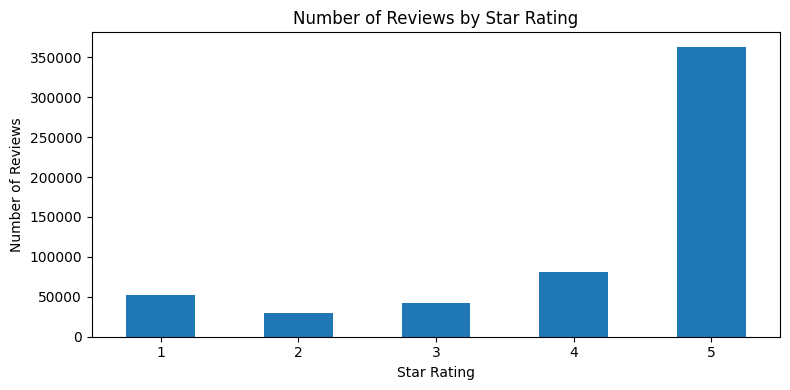

In [7]:
rating_counts = df["Score"].value_counts().sort_index()
display(rating_counts.rename("Review_Count").to_frame())

rating_counts.plot(kind="bar", figsize=(8, 4))
plt.title("Number of Reviews by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 8. Check the sentiment distribution

,Review_Count
Sentiment,
Negative,82037
Neutral,42640
Positive,443777


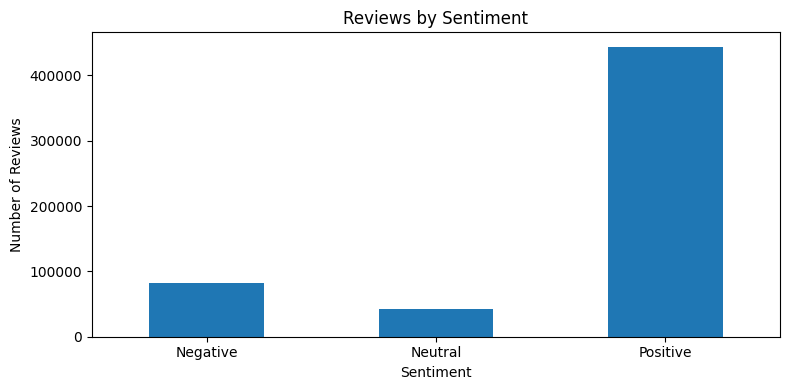

Note: 1–2 stars are Negative, 3 stars are Neutral, and 4–5 stars are Positive.


In [8]:
sentiment_counts = df["Sentiment"].value_counts().reindex(
    ["Negative", "Neutral", "Positive"], fill_value=0
)
display(sentiment_counts.rename("Review_Count").to_frame())

sentiment_counts.plot(kind="bar", figsize=(8, 4))
plt.title("Reviews by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Note: 1–2 stars are Negative, 3 stars are Neutral, and 4–5 stars are Positive.")

### 9. Check review activity over time

,ReviewYear,Review_Count,Average_Rating
4,2003,132,4.325758
5,2004,561,4.392157
6,2005,1335,4.445693
7,2006,6671,4.313446
8,2007,22300,4.391345
9,2008,34163,4.345344
10,2009,55326,4.300365
11,2010,85884,4.198838
12,2011,163299,4.143804
13,2012,198659,4.117885


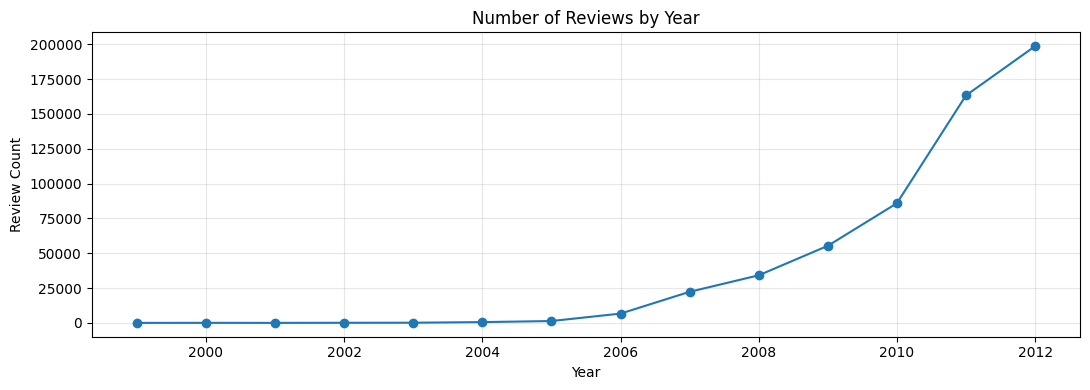

In [9]:
yearly_reviews = df.groupby("ReviewYear").agg(
    Review_Count=("Id", "count"),
    Average_Rating=("Score", "mean")
).reset_index()

display(yearly_reviews.tail(10))

plt.figure(figsize=(11, 4))
plt.plot(yearly_reviews["ReviewYear"], yearly_reviews["Review_Count"], marker="o")
plt.title("Number of Reviews by Year")
plt.xlabel("Year")
plt.ylabel("Review Count")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 10. Find products with the most reviews

,ProductId,Review_Count,Average_Rating
71170,B007JFMH8M,913,4.58
37898,B0026RQTGE,632,4.59
42257,B002QWHJOU,632,4.59
42264,B002QWP8H0,632,4.59
42263,B002QWP89S,632,4.59
46205,B003B3OOPA,623,4.74
28624,B001EO5Q64,567,4.75
68860,B006HYLW32,564,4.31
35243,B001RVFEP2,564,4.31
37798,B0026KPDG8,564,4.31


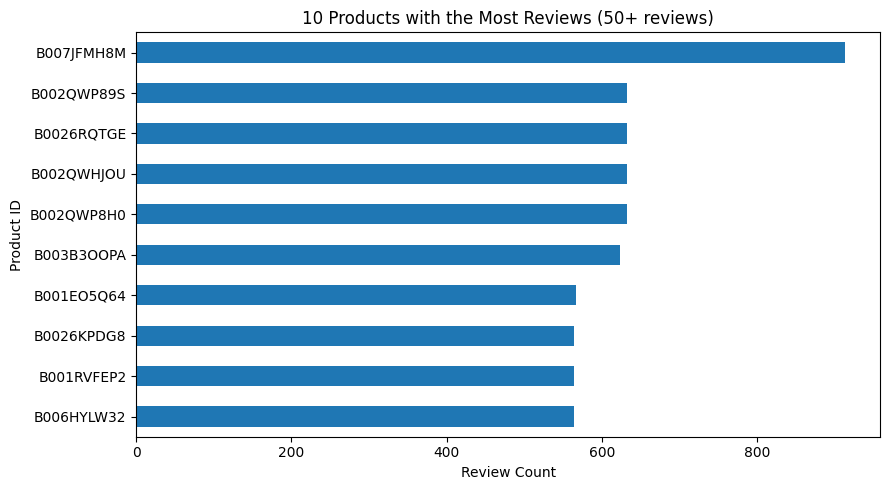

In [10]:
product_summary = df.groupby("ProductId").agg(
    Review_Count=("Id", "count"),
    Average_Rating=("Score", "mean")
).reset_index()

# Use products with at least 50 reviews for a more useful comparison.
popular_products = product_summary[product_summary["Review_Count"] >= 50]
top_products = popular_products.sort_values("Review_Count", ascending=False).head(10)

display(top_products.round({"Average_Rating": 2}))

top_products.sort_values("Review_Count").plot(
    x="ProductId", y="Review_Count", kind="barh", legend=False, figsize=(9, 5)
)
plt.title("10 Products with the Most Reviews (50+ reviews)")
plt.xlabel("Review Count")
plt.ylabel("Product ID")
plt.tight_layout()
plt.show()

### 11. Look at reviewer activity

In [11]:
reviewer_activity = df.groupby("UserId").agg(
    Review_Count=("Id", "count"),
    Average_Rating=("Score", "mean")
).reset_index()

top_reviewers = reviewer_activity.sort_values("Review_Count", ascending=False).head(10)
display(top_reviewers.round({"Average_Rating": 2}))

,UserId,Review_Count,Average_Rating
182011,A3OXHLG6DIBRW8,448,4.54
65586,A1YUL9PCJR3JTY,421,4.49
252275,AY12DBB0U420B,389,4.65
82919,A281NPSIMI1C2R,365,4.84
66162,A1Z54EM24Y40LL,256,4.45
55736,A1TMAVN4CEM8U8,204,4.83
110863,A2MUGFV2TDQ47K,201,3.75
191283,A3TVZM3ZIXG8YW,199,1.00
183161,A3PJZ8TU8FDQ1K,178,4.60
238453,AQQLWCMRNDFGI,176,3.95


### 12. Analyze helpful votes

Rows where helpfulness numerator is greater than denominator: 2


,Score,Reviews,Average_Helpfulness,Median_Helpfulness
0,1,52268,0.539,0.50
1,2,29769,0.566,0.60
2,3,42640,0.626,0.75
3,4,80655,0.791,1.00
4,5,363122,0.872,1.00


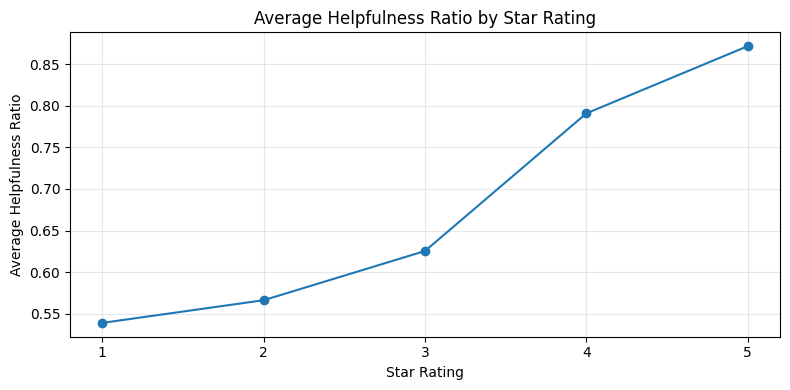

In [12]:
print(
    "Rows where helpfulness numerator is greater than denominator:",
    int((df["HelpfulnessNumerator"] > df["HelpfulnessDenominator"]).sum())
)

helpfulness_by_rating = df.groupby("Score").agg(
    Reviews=("Id", "count"),
    Average_Helpfulness=("HelpfulnessRatio", "mean"),
    Median_Helpfulness=("HelpfulnessRatio", "median")
).reset_index()

display(helpfulness_by_rating.round(3))

helpfulness_by_rating.plot(
    x="Score", y="Average_Helpfulness", marker="o", legend=False, figsize=(8, 4)
)
plt.title("Average Helpfulness Ratio by Star Rating")
plt.xlabel("Star Rating")
plt.ylabel("Average Helpfulness Ratio")
plt.xticks([1, 2, 3, 4, 5])
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 13. Compare review length with sentiment

,Review_Count,Average_Review_Words,Median_Review_Words,Average_Summary_Words
Sentiment,,,,
Negative,82037,88.31,64.0,4.36
Neutral,42640,95.65,70.0,4.76
Positive,443777,77.30,54.0,4.01


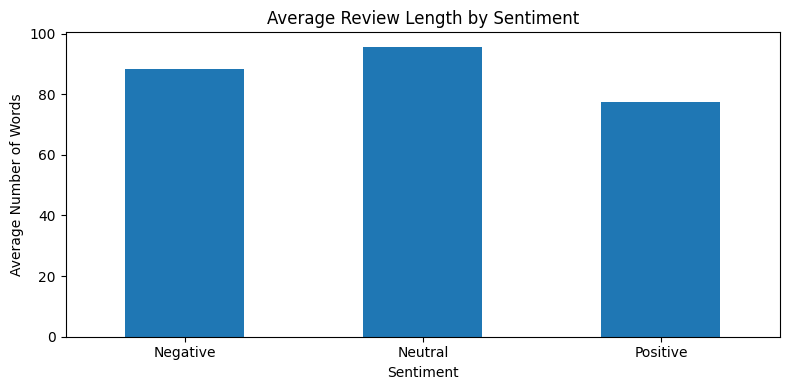

In [13]:
length_by_sentiment = df.groupby("Sentiment").agg(
    Review_Count=("Id", "count"),
    Average_Review_Words=("ReviewLength", "mean"),
    Median_Review_Words=("ReviewLength", "median"),
    Average_Summary_Words=("SummaryLength", "mean")
).reindex(["Negative", "Neutral", "Positive"])

display(length_by_sentiment.round(2))

length_by_sentiment["Average_Review_Words"].plot(kind="bar", figsize=(8, 4))
plt.title("Average Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Average Number of Words")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 14. Decide which columns the RNN should use

For the sentiment model, I will combine **Summary and Text**, because the summary is part of what the customer says about the product.

`Score` will be used to create the answer the model should learn: Negative (1–2 stars), Neutral (3 stars), and Positive (4–5 stars).

I have analyzed `ProductId`, `UserId`, `ProfileName`, `Time`, and helpfulness columns above. I will not feed those IDs and metadata directly into this text model: they do not express the review's wording, and `Score` must not be an input because it is used to create the target label.

In [14]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)       # remove HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

model_df = df[["Summary", "Text", "Score", "Sentiment"]].copy()
model_df["ReviewText"] = (
    model_df["Summary"].fillna("").astype(str) + " " +
    model_df["Text"].fillna("").astype(str)
).map(clean_text)

model_df = model_df[model_df["ReviewText"].str.strip() != ""].copy()
model_df["Label"] = model_df["Sentiment"].map(
    {"Negative": 0, "Neutral": 1, "Positive": 2}
).astype(int)

display(model_df[["Summary", "Text", "Sentiment", "Label"]].head())
print("Rows available for modelling:", len(model_df))

,Summary,Text,Sentiment,Label
0,Good Quality Dog Food,I have bought several of the Vitality canned dog food products and have found them all to be of ...,Positive,2
1,Not as Advertised,Product arrived labeled as Jumbo Salted Peanuts...the peanuts were actually small sized unsalted...,Negative,0
2,"""Delight"" says it all","This is a confection that has been around a few centuries. It is a light, pillowy citrus gelati...",Positive,2
3,Cough Medicine,If you are looking for the secret ingredient in Robitussin I believe I have found it. I got thi...,Negative,0
4,Great taffy,Great taffy at a great price. There was a wide assortment of yummy taffy. Delivery was very qu...,Positive,2


Rows available for modelling: 568454


### 15. Select a manageable sample for model training

The full dataset is used for the analysis above. To keep RNN training manageable on a regular laptop, I will use a stratified sample of up to 60,000 reviews for modelling. This keeps the three sentiment groups in roughly the same proportions as the full dataset.

In [15]:
MAX_REVIEWS_FOR_MODEL = 60000

if len(model_df) > MAX_REVIEWS_FOR_MODEL:
    sample_parts = []
    for sentiment, group in model_df.groupby("Sentiment"):
        take = round(MAX_REVIEWS_FOR_MODEL * len(group) / len(model_df))
        take = max(1, min(take, len(group)))
        sample_parts.append(group.sample(n=take, random_state=42))

    model_df = pd.concat(sample_parts).sample(frac=1, random_state=42)

model_df = model_df.reset_index(drop=True)

print("Rows used for modelling:", len(model_df))
display(model_df["Sentiment"].value_counts().rename("Review_Count").to_frame())

Rows used for modelling: 60000


,Review_Count
Sentiment,
Positive,46840
Negative,8659
Neutral,4501


### 16. Split the reviews into train, validation and test sets

The arrays are converted to normal Python lists before splitting. This also avoids the Arrow-backed array indexing error that can happen with some pandas/scikit-learn setups.

In [16]:
X = model_df["ReviewText"].astype(str).tolist()
y = model_df["Label"].astype(int).tolist()

X_train_text, X_temp_text, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

X_val_text, X_test_text, y_val, y_test = train_test_split(
    X_temp_text, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

y_train = np.array(y_train, dtype=np.int32)
y_val = np.array(y_val, dtype=np.int32)
y_test = np.array(y_test, dtype=np.int32)

print("Training reviews:", len(X_train_text))
print("Validation reviews:", len(X_val_text))
print("Testing reviews:", len(X_test_text))

Training reviews: 48000
Validation reviews: 6000
Testing reviews: 6000


### 17. Convert text into numbers

In [17]:
MAX_WORDS = 30000
MAX_LENGTH = 120

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train_text)

X_train_seq = pad_sequences(
    tokenizer.texts_to_sequences(X_train_text),
    maxlen=MAX_LENGTH, padding="post", truncating="post"
)
X_val_seq = pad_sequences(
    tokenizer.texts_to_sequences(X_val_text),
    maxlen=MAX_LENGTH, padding="post", truncating="post"
)
X_test_seq = pad_sequences(
    tokenizer.texts_to_sequences(X_test_text),
    maxlen=MAX_LENGTH, padding="post", truncating="post"
)

print("Training shape:", X_train_seq.shape)
print("Validation shape:", X_val_seq.shape)
print("Testing shape:", X_test_seq.shape)

Training shape: (48000, 120)
Validation shape: (6000, 120)
Testing shape: (6000, 120)


### 18. Build the RNN model

In [18]:
model = Sequential([
    Input(shape=(MAX_LENGTH,)),
    Embedding(input_dim=MAX_WORDS, output_dim=48, mask_zero=True),
    SimpleRNN(48),
    Dropout(0.3),
    Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 120, 48)             │       1,440,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ simple_rnn (SimpleRNN)               │ (None, 48)                  │           4,656 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 48)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 3)                   │             147 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,444,803 (5.51 MB)

 Trainable params: 1,444,803 (5.51 MB)

 Non-trainable params: 0 (0.00 B)

### 19. Train the model

In [19]:
# Give more weight to less common sentiment groups.
class_labels = np.array([0, 1, 2])
weights = compute_class_weight(
    class_weight="balanced",
    classes=class_labels,
    y=y_train
)
class_weights = {int(label): float(weight) for label, weight in zip(class_labels, weights)}
print("Class weights:", class_weights)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_seq,
    y_train,
    validation_data=(X_val_seq, y_val),
    epochs=5,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)

Class weights: {0: 2.30980222318464, 1: 4.443210219383505, 2: 0.4269854824935952}
Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 26s 64ms/step - accuracy: 0.4430 - loss: 1.0651 - val_accuracy: 0.7798 - val_loss: 0.6682
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 25s 67ms/step - accuracy: 0.7061 - loss: 0.7600 - val_accuracy: 0.7298 - val_loss: 0.7292
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 25s 67ms/step - accuracy: 0.8545 - loss: 0.3980 - val_accuracy: 0.7732 - val_loss: 0.6283
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 25s 67ms/step - accuracy: 0.8763 - loss: 0.2573 - val_accuracy: 0.7938 - val_loss: 0.6095
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 25s 67ms/step - accuracy: 0.9310 - loss: 0.1443 - val_accuracy: 0.8000 - val_loss: 0.6578


### 20. Check training progress

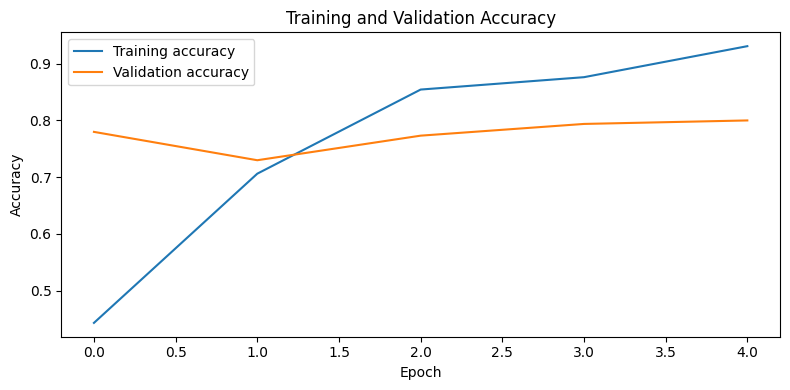

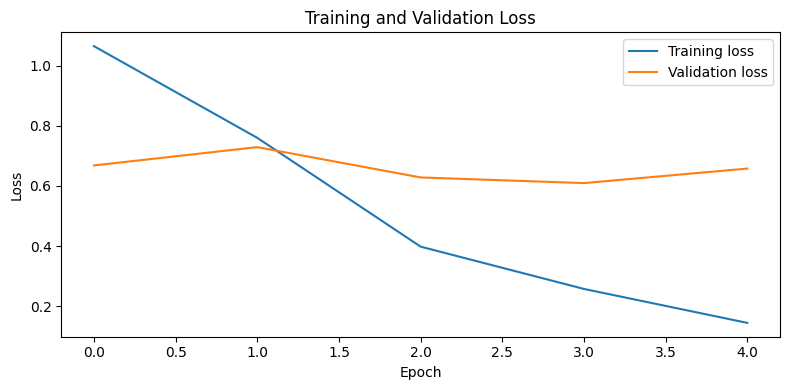

In [20]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()

### 21. Evaluate the model on test reviews

In [21]:
probabilities = model.predict(X_test_seq, batch_size=256, verbose=0)
predictions = np.argmax(probabilities, axis=1)

sentiment_names = ["Negative", "Neutral", "Positive"]

print("Test accuracy:", round(accuracy_score(y_test, predictions), 4))
print("Macro F1-score:", round(f1_score(y_test, predictions, average="macro"), 4))
print("Weighted F1-score:", round(f1_score(y_test, predictions, average="weighted"), 4))
print()
print(classification_report(
    y_test,
    predictions,
    labels=[0, 1, 2],
    target_names=sentiment_names,
    zero_division=0
))

Test accuracy: 0.8002
Macro F1-score: 0.6
Weighted F1-score: 0.8171

              precision    recall  f1-score   support

    Negative       0.55      0.69      0.61       866
     Neutral       0.23      0.35      0.28       450
    Positive       0.95      0.86      0.91      4684

    accuracy                           0.80      6000
   macro avg       0.58      0.63      0.60      6000
weighted avg       0.84      0.80      0.82      6000



,Predicted Negative,Predicted Neutral,Predicted Positive
Actual Negative,598,180,88
Actual Neutral,181,157,112
Actual Positive,301,337,4046


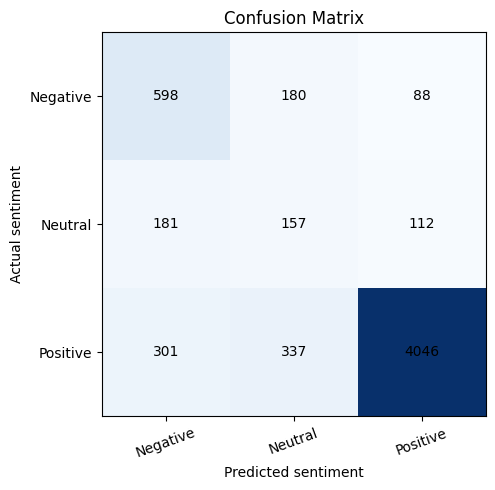

In [22]:
matrix = confusion_matrix(y_test, predictions, labels=[0, 1, 2])
display(pd.DataFrame(
    matrix,
    index=["Actual Negative", "Actual Neutral", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Neutral", "Predicted Positive"]
))

plt.figure(figsize=(6, 5))
plt.imshow(matrix, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted sentiment")
plt.ylabel("Actual sentiment")
plt.xticks([0, 1, 2], sentiment_names, rotation=20)
plt.yticks([0, 1, 2], sentiment_names)

for row in range(3):
    for col in range(3):
        plt.text(col, row, matrix[row, col], ha="center", va="center")

plt.tight_layout()
plt.show()

### 22. Try some new reviews

In [23]:
new_reviews = [
    "This product tastes great and I would buy it again.",
    "The quality was poor and I will not buy it again.",
    "It is an average product. Nothing special."
]

new_reviews_clean = [clean_text(review) for review in new_reviews]
new_reviews_seq = pad_sequences(
    tokenizer.texts_to_sequences(new_reviews_clean),
    maxlen=MAX_LENGTH, padding="post", truncating="post"
)

new_probabilities = model.predict(new_reviews_seq, verbose=0)
new_predictions = np.argmax(new_probabilities, axis=1)

for review, predicted_label, probabilities_for_review in zip(
    new_reviews, new_predictions, new_probabilities
):
    print("Review:", review)
    print("Predicted sentiment:", sentiment_names[predicted_label])
    print("Class probabilities:", {
        sentiment_names[i]: round(float(probabilities_for_review[i]), 3)
        for i in range(3)
    })
    print()

Review: This product tastes great and I would buy it again.
Predicted sentiment: Neutral
Class probabilities: {'Negative': 0.03, 'Neutral': 0.64, 'Positive': 0.33}

Review: The quality was poor and I will not buy it again.
Predicted sentiment: Negative
Class probabilities: {'Negative': 0.805, 'Neutral': 0.178, 'Positive': 0.017}

Review: It is an average product. Nothing special.
Predicted sentiment: Neutral
Class probabilities: {'Negative': 0.095, 'Neutral': 0.65, 'Positive': 0.255}



### 23. Save the model

In [24]:
model.save("customer_review_rnn.keras")

with open("customer_review_tokenizer.json", "w", encoding="utf-8") as file:
    file.write(tokenizer.to_json())

print("Model saved as customer_review_rnn.keras")
print("Tokenizer saved as customer_review_tokenizer.json")

Model saved as customer_review_rnn.keras
Tokenizer saved as customer_review_tokenizer.json


### Conclusion

I checked the complete dataset and used its different columns for data quality checks and analysis. The product, reviewer, date, rating, summary, review text, and helpful-vote fields each provide a different view of customer feedback.

For sentiment prediction, I trained a SimpleRNN on the review summary and full text. The rating was converted to three labels: Negative (1–2 stars), Neutral (3 stars), and Positive (4–5 stars). The test results show how well this rating-based sentiment model performed on reviews not used during training.

One limitation is that star ratings are used as the sentiment labels, so the model learns rating-based sentiment rather than independently human-annotated sentiment. RNN predictions can also be wrong for sarcasm or mixed opinions.